# Association Rule Mining — H1 to H4
**Owner:** Mohid · **DSAI 4102** · **Seed:** 42 · **Team-integration version (November 2026)**

This notebook works with **Mouaz's updated project**. First run `01_data_eda.ipynb`, then `02_clustering.ipynb`, then `05_cluster_rules.ipynb` in that project. These create the files needed in `data/`. Next, use **Kernel → Restart Kernel and Run All Cells** here.

**Important changes:** Official ratings Parquet files do **not** contain `genres`. We use `src.data_utils.liked_ratings_with_genres()` with `movies_clean.parquet`, and use Mouaz's updated `mine_rules(..., share_threshold=0.20)` without overwriting his `rules.py`.

Experiments run on the **official complete-history 5% user sample** for laptop practicality. They do not automatically represent all 200,948 MovieLens users. The notebook labels the sample and includes a cross-check with `cluster_rules.csv` generated by Mouaz on the full group data. Never upload the `data/` folder to GitHub.

In [1]:
# Setup: locate the updated GitHub project, including if Jupyter starts in your home folder.
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

SEED = 42
rng = np.random.default_rng(SEED)

# If several project copies exist, set PROJECT_OVERRIDE to the exact NEW project folder.
# Otherwise leave it as None and the notebook looks for data_utils.py and official files.
PROJECT_OVERRIDE = None

if PROJECT_OVERRIDE:
    PROJECT = Path(PROJECT_OVERRIDE).expanduser().resolve()
else:
    home = Path.home()
    downloads = home / "Downloads"
    candidates = [Path.cwd(), Path.cwd().parent, *Path.cwd().parents]
    for outer in downloads.glob("movie-audience-data-mining-project*"):
        candidates.append(outer)
        candidates.extend(outer.glob("movie-audience-data-mining-project*"))
    valid = []
    seen = set()
    for p in candidates:
        p = p.resolve()
        if p not in seen and (p / "src" / "rules.py").is_file() and (p / "src" / "data_utils.py").is_file():
            valid.append(p)
        seen.add(p)
    if not valid:
        raise FileNotFoundError("Updated project not found. Set PROJECT_OVERRIDE to your new GitHub project's root folder.")
    # Prefer the repo that has Mouaz's generated official artifacts.
    def project_score(p):
        return (sum((p / "data" / name).exists() for name in
                    ("movies_clean.parquet", "sample_ratings.parquet", "clean_ratings.parquet", "cluster_rules.csv")),
                (p / "src" / "rules.py").stat().st_mtime)
    PROJECT = max(valid, key=project_score)

if not (PROJECT / "src" / "data_utils.py").is_file():
    raise FileNotFoundError(f"src/data_utils.py missing from {PROJECT}. Use Mouaz's updated repo.")
sys.path.insert(0, str(PROJECT))
from src.data_utils import liked_ratings_with_genres
from src.rules import build_transactions, mine_rules

DATA = PROJECT / "data"
FIG = PROJECT / "figures"
FIG.mkdir(exist_ok=True, parents=True)
FINAL_SHARE_THRESHOLD = 0.20  # Mouaz's default for association rules
FINAL_SUPPORT = 0.25
FINAL_CONFIDENCE = 0.85
LIFT_CUTOFF = 1.20

print("PROJECT:", PROJECT)
print("DATA:", DATA)
print("SHARED RULES FILE:", sys.modules["src.rules"].__file__)
print("Genre share:", FINAL_SHARE_THRESHOLD, "Support:", FINAL_SUPPORT, "Confidence:", FINAL_CONFIDENCE)

PROJECT: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main
DATA: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\data
SHARED RULES FILE: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\src\rules.py
Genre share: 0.2 Support: 0.25 Confidence: 0.85


## Data source — use Mouaz's official files

Mouaz's official `sample_ratings.parquet` / `clean_ratings.parquet` contain ratings but **no genre column**. His `movies_clean.parquet` contains a `movieId` column and one genre-indicator column per genre (18 genres). `liked_ratings_with_genres()` joins the genres and keeps only liked ratings (rating ≥ 4.0). We then pass this joined DataFrame to `build_transactions()` and `mine_rules()`.

The official **5% sample contains all ratings for its sampled users**, not merely the first rows of the big CSV. This is important because genre-share calculations require complete per-user histories. This notebook refuses to fall back to a truncated raw dataset.

In [2]:
# Load Mouaz's artifacts. No manually prepared data or incomplete CSV fallback.
sample_path = DATA / "sample_ratings.parquet"
full_path = DATA / "clean_ratings.parquet"
movies_path = DATA / "movies_clean.parquet"
if not movies_path.exists() or not (sample_path.exists() or full_path.exists()):
    raise FileNotFoundError(
        "Run notebooks/01_data_eda.ipynb from the UPDATED GitHub project first: "
        "data/ must contain movies_clean.parquet and sample_ratings.parquet (or clean_ratings.parquet)."
    )

ratings_source_path = sample_path if sample_path.exists() else full_path
raw_ratings = pd.read_parquet(ratings_source_path)
movies_clean = pd.read_parquet(movies_path)
assert {"movieId", "rating"}.issubset(raw_ratings.columns)
assert "movieId" in movies_clean.columns
USER = "userId" if "userId" in raw_ratings.columns else "user"
assert USER in raw_ratings.columns

# The helper provided in Mouaz's latest src/data_utils.py.
# IMPORTANT: Mouaz's helper indexes genres with row.values, which must be a Boolean mask.
# If genre flags are stored as integer 0/1, indexing would otherwise select wrong names.
genre_cols = movies_clean.columns.drop("movieId")
if not movies_clean[genre_cols].isin([0, 1, True, False]).all().all():
    raise ValueError("movies_clean.parquet must have Boolean or 0/1 indicator columns for genres.")
movies_clean = movies_clean.copy()
movies_clean[genre_cols] = movies_clean[genre_cols].astype(bool)
ratings_df = liked_ratings_with_genres(raw_ratings, movies_clean)
assert {USER, "rating", "genres"}.issubset(ratings_df.columns)
all_user_ids = np.sort(raw_ratings[USER].dropna().unique())

print("Rating source:", ratings_source_path.name)
print("Rating rows:", len(raw_ratings), "distinct users:", len(all_user_ids))
print("Liked ratings with genre column:", len(ratings_df))
print("Genre indicator columns in movies_clean:", len(genre_cols), "(converted to Boolean for data_utils)")
print("Note: statistics below refer to this sampled-user dataset, not necessarily the full MovieLens audience.")
display(ratings_df[[USER, "movieId", "rating", "genres"]].head(3))

Rating source: sample_ratings.parquet
Rating rows: 1599232 distinct users: 10047
Liked ratings with genre column: 789406
Genre indicator columns in movies_clean: 18 (converted to Boolean for data_utils)
Note: statistics below refer to this sampled-user dataset, not necessarily the full MovieLens audience.


,userId,movieId,rating,genres
0,1,17,4.0,Drama|Romance
3,1,30,5.0,Crime|Drama
4,1,32,5.0,Mystery|Sci-Fi|Thriller


## H1 — Genre transactions and user-share comparison

A liked movie is rated **4.0 or higher**. `build_transactions()` returns one Boolean row per user. A genre enters the basket when its share of liked movies reaches the chosen threshold; multi-genre films contribute to multiple genres. The original work plan requests **0.10 and 0.20**; Mouaz also asked to compare **0.30**.

Mouaz found that **0.10 makes baskets too dense** (for example, Drama in nearly every basket), while **0.30 makes rules sparse**. His updated shared default is therefore **0.20**. This notebook measures all three on the same official sample, so the numerical explanation comes from real output.

In [3]:
# H1: side-by-side comparison of the three thresholds requested by Mouaz.
SHARE_VALUES = (0.10, 0.20, 0.30)
transactions_by_share = {}
h1_rows = []
for share in SHARE_VALUES:
    tx = build_transactions(ratings_df, all_user_ids, share_threshold=share)
    transactions_by_share[share] = tx
    h1_rows.append({
        "genre_share_threshold": share,
        "users_retained": len(tx),
        "users_without_likes": len(all_user_ids) - len(tx),
        "mean_genres_per_basket": float(tx.sum(axis=1).mean()) if len(tx) else 0.0,
        "Drama_%": float(tx["Drama"].mean() * 100) if "Drama" in tx else 0.0,
        "Comedy_%": float(tx["Comedy"].mean() * 100) if "Comedy" in tx else 0.0,
    })
transactions = transactions_by_share[FINAL_SHARE_THRESHOLD]
h1_summary = pd.DataFrame(h1_rows)
print("H1: Same rating source and user set at every genre-share threshold")
display(h1_summary.round(2))

popularity = pd.DataFrame({
    f"Share {share:.2f} / users (%)": 100 * tx.mean(axis=0)
    for share, tx in transactions_by_share.items()
}).fillna(0).sort_values("Share 0.10 / users (%)", ascending=False)
display(popularity.round(1))
display(transactions.head())

H1: Same rating source and user set at every genre-share threshold


,genre_share_threshold,users_retained,users_without_likes,mean_genres_per_basket,Drama_%,Comedy_%
0,0.1,10039,8,8.78,99.00,94.37
1,0.2,10039,8,5.38,95.73,77.73
2,0.3,10039,8,3.17,86.48,50.07


,Share 0.10 / users (%),Share 0.20 / users (%),Share 0.30 / users (%)
genres,,,
Drama,99.0,95.7,86.5
Comedy,94.4,77.7,50.1
Thriller,91.0,71.2,41.4
Action,88.0,68.1,44.8
Adventure,85.2,58.7,32.8
Crime,83.0,46.7,16.7
Romance,74.1,37.2,14.6
Sci-Fi,68.1,35.7,15.5
Fantasy,48.5,14.2,4.2


genres,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
userId,,,,,,,,,,,,,,,,,,
1,False,False,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False
80,True,True,False,False,False,False,False,True,False,False,False,False,False,False,True,True,False,False
104,False,False,False,False,True,True,False,True,False,False,False,False,False,True,True,True,False,False
113,False,False,False,False,True,True,False,True,False,False,False,False,False,False,False,True,False,False
125,True,True,False,False,False,True,False,True,False,False,False,False,False,True,True,True,False,False


**H1 interpretation.** Compare the three rows above. A 10% basket may include so many genres that most users look alike, leading to high-confidence rules that mainly reflect popularity. Raising the requirement to 20% produces more selective preferences; 30% can discard potentially useful co-preferences. We therefore adopt **genre share = 0.20**, as in Mouaz's updated `mine_rules()`. This is **different** from the association-rule *minimum support* value of 0.25.

## H2 — Apriori versus FP-Growth

Apriori enumerates candidate itemsets; FP-Growth mines frequent itemsets using a tree. Both must agree on itemsets and support when given the same input. We benchmark transactions built using **genre share = 0.20**, with supports `0.10` and `0.005`.

To keep the low-support experiment practical, the benchmarking subset contains at most 400 users. The 10%, 25%, 50% and 100% percentages refer to that subset, **not** to all MovieLens users. Each measurement is repeated three times.

In [4]:
BENCHMARK_MAX_USERS = 400  # Larger benchmarks may need significant memory.
benchmark_source = transactions.sample(frac=1, random_state=SEED)
benchmark_data = benchmark_source.head(BENCHMARK_MAX_USERS)
print("Benchmark transactions:", len(benchmark_data), "out of", len(transactions))

frequent_a = apriori(benchmark_data, min_support=0.10, use_colnames=True)
frequent_f = fpgrowth(benchmark_data, min_support=0.10, use_colnames=True)
def support_lookup(frame):
    return {tuple(sorted(itemset)): float(support)
            for itemset, support in zip(frame["itemsets"], frame["support"])}
a_lookup = support_lookup(frequent_a)
f_lookup = support_lookup(frequent_f)
assert a_lookup.keys() == f_lookup.keys(), "Itemsets differ between algorithms"
assert all(np.isclose(a_lookup[item], f_lookup[item], atol=1e-10) for item in a_lookup), "Supports differ"
print("PASS: identical itemsets and supports (", len(a_lookup), "itemsets )")

Benchmark transactions: 400 out of 10039
PASS: identical itemsets and supports ( 147 itemsets )


,support,users,algorithm,avg_seconds
0,0.100,40,Apriori,0.0110
1,0.100,40,FP-Growth,0.0049
2,0.100,100,Apriori,0.0056
3,0.100,100,FP-Growth,0.0056
4,0.100,200,Apriori,0.0075
5,0.100,200,FP-Growth,0.0067
6,0.100,400,Apriori,0.0046
7,0.100,400,FP-Growth,0.0071
8,0.005,40,Apriori,0.0112
9,0.005,40,FP-Growth,0.0064


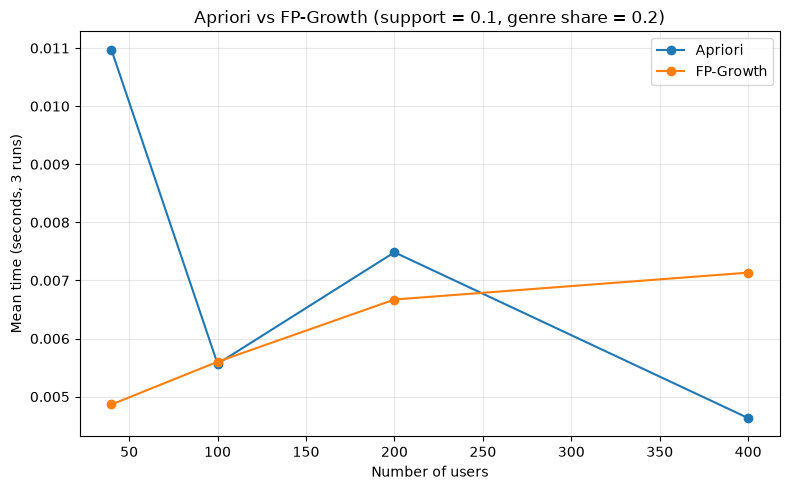

Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\figures\h2_timing_support_010.png


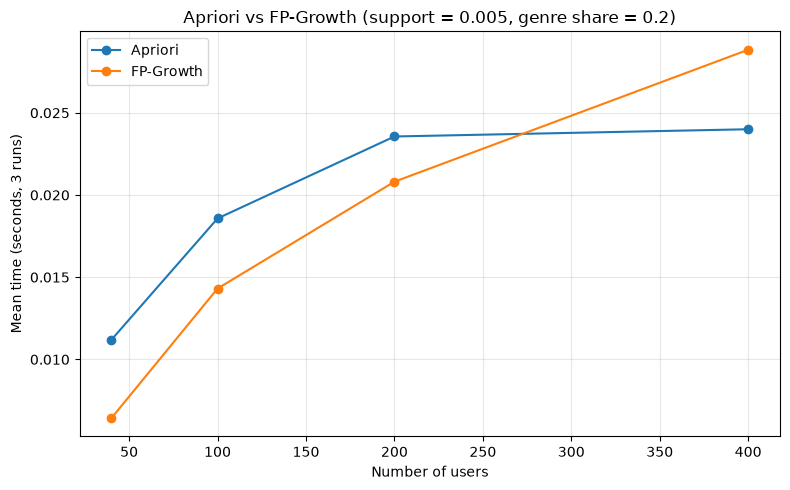

Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\figures\h2_timing_support_0005.png


In [5]:
# H2: timing at two supports, four sizes, three repeats each.
bench_rows = []
for support in (0.10, 0.005):
    for frac in (0.10, 0.25, 0.50, 1.00):
        n = max(1, round(len(benchmark_data) * frac))
        subset = benchmark_data.iloc[:n]
        for name, algo in (("Apriori", apriori), ("FP-Growth", fpgrowth)):
            runs = []
            for repeat in range(3):
                t0 = time.perf_counter()
                algo(subset, min_support=support, use_colnames=True)
                runs.append(time.perf_counter() - t0)
            bench_rows.append({"support": support, "users": n, "algorithm": name,
                               "avg_seconds": float(np.mean(runs))})
bench_df = pd.DataFrame(bench_rows)
display(bench_df.round(4))

for support, filename in ((0.10, "h2_timing_support_010.png"), (0.005, "h2_timing_support_0005.png")):
    frame = bench_df.loc[bench_df["support"] == support]
    fig, ax = plt.subplots(figsize=(8, 5))
    for algo in ("Apriori", "FP-Growth"):
        line = frame.loc[frame["algorithm"] == algo]
        ax.plot(line["users"], line["avg_seconds"], marker="o", label=algo)
    ax.set(title=f"Apriori vs FP-Growth (support = {support}, genre share = {FINAL_SHARE_THRESHOLD})",
           xlabel="Number of users", ylabel="Mean time (seconds, 3 runs)")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / filename, dpi=180)
    plt.show()
    print("Saved:", FIG / filename)

**H2 interpretation.** Compare the printed timings rather than expecting perfectly increasing lines. At low minimum support (`0.005`), the algorithms consider many more itemsets; FP-Growth often benefits because Apriori generates more candidate combinations. Short measurements are noisy, so each point averages three runs. Both algorithms returned identical itemsets and support values in the controlled comparison.

## H3 — Support, confidence and lift

- **Genre share = 0.20:** Which genres qualify for each user's basket.
- **Minimum support = 0.25:** An itemset must appear in at least one quarter of user baskets.
- **Minimum confidence = 0.85:** At least 85% of transactions containing the antecedent must also contain the consequent.
- **Lift > 1.20:** The association is stronger than expected from the consequent's overall popularity.

**Why 0.25 / 0.85?** We tested alternatives and aim for roughly 20–200 understandable rules *after the lift filter*, rather than thousands of weak or redundant associations. Support 0.25 avoids very rare combinations; confidence 0.85 requires high conditional reliability. **These values are an empirically selected, practical compromise, not a mathematical optimum.** The three-way genre-share comparison below tests whether they still work with Mouaz's 0.20 preference threshold.

In [6]:
# Required work-plan grid: supports 0.01, 0.02, 0.05, 0.10 by confidences 0.50, 0.60, 0.70.
# Use a reproducible smaller subset; low support can create many candidate rules.
H3_GRID_MAX_USERS = 323
h3_grid_data = transactions.sample(frac=1, random_state=SEED).head(H3_GRID_MAX_USERS)
threshold_rows = []
for support in (0.01, 0.02, 0.05, 0.10):
    itemsets = fpgrowth(h3_grid_data, min_support=support, use_colnames=True)
    viable = not itemsets.empty and itemsets["itemsets"].map(len).ge(2).any()
    for confidence in (0.50, 0.60, 0.70):
        if viable:
            rs = association_rules(itemsets, num_itemsets=len(h3_grid_data),
                                   metric="confidence", min_threshold=confidence)
            count, strong = len(rs), int(rs["lift"].gt(LIFT_CUTOFF).sum())
        else:
            count = strong = 0
        threshold_rows.append({"support": support, "confidence": confidence,
                               "rules": count, "lift_above_1_2": strong})
threshold_df = pd.DataFrame(threshold_rows)
threshold_grid = threshold_df.assign(
    summary=lambda t: t["rules"].astype(str) + " total / " + t["lift_above_1_2"].astype(str) + " strong"
).pivot(index="support", columns="confidence", values="summary")
display(threshold_grid)
threshold_df.to_csv(FIG / "h3_threshold_grid.csv", index=False)
print("Grid users:", len(h3_grid_data), "Saved:", FIG / "h3_threshold_grid.csv")

confidence,0.5,0.6,0.7
support,,,
0.01,4872 total / 3254 strong,3423 total / 2286 strong,2536 total / 1741 strong
0.02,2590 total / 1556 strong,1927 total / 1178 strong,1403 total / 882 strong
0.05,1113 total / 555 strong,835 total / 471 strong,638 total / 385 strong
0.10,659 total / 314 strong,498 total / 264 strong,381 total / 216 strong


Grid users: 323 Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\figures\h3_threshold_grid.csv


### H3 — Tuning support and confidence on 1,000 users

Use **genre share = 0.20** for this test to match the team's latest code. The figures here refer to a reproducible **1,000-user subset** of the official 5% sample. We'll also test the chosen thresholds on the entire 5% sample.

In [7]:
H3_TARGET_USERS = 1000
h3_rng = np.random.default_rng(SEED)
h3_ids = h3_rng.choice(all_user_ids, size=min(H3_TARGET_USERS, len(all_user_ids)), replace=False)
h3_transactions = build_transactions(ratings_df, h3_ids, share_threshold=FINAL_SHARE_THRESHOLD)
strong_count_rows = []
for support in (0.20, 0.25, 0.30):
    itemsets = fpgrowth(h3_transactions, min_support=support, use_colnames=True)
    for confidence in (0.80, 0.85, 0.90):
        if itemsets.empty or not itemsets["itemsets"].map(len).ge(2).any():
            strong = 0
        else:
            rs = association_rules(itemsets, num_itemsets=len(h3_transactions),
                                   metric="confidence", min_threshold=confidence)
            strong = int(rs["lift"].gt(LIFT_CUTOFF).sum())
        strong_count_rows.append({"support":support, "confidence":confidence, "strong_rules":strong})
threshold_choices = pd.DataFrame(strong_count_rows)
display(threshold_choices)
print("Settings with 20–200 strong rules:")
display(threshold_choices[threshold_choices["strong_rules"].between(20, 200)])

,support,confidence,strong_rules
0,0.20,0.80,62
1,0.20,0.85,52
2,0.20,0.90,25
3,0.25,0.80,35
4,0.25,0.85,29
5,0.25,0.90,13
6,0.30,0.80,21
7,0.30,0.85,17
8,0.30,0.90,8


Settings with 20–200 strong rules:


,support,confidence,strong_rules
0,0.20,0.80,62
1,0.20,0.85,52
2,0.20,0.90,25
3,0.25,0.80,35
4,0.25,0.85,29
6,0.30,0.80,21


In [8]:
# Top 15 rules at the proposed team thresholds, on the same 1,000 users.
selected_rules = mine_rules(ratings_df, h3_ids, FINAL_SUPPORT, FINAL_CONFIDENCE,
                            share_threshold=FINAL_SHARE_THRESHOLD)
strong_rules = selected_rules[selected_rules["lift"] > LIFT_CUTOFF].copy()
top_15 = strong_rules.sort_values("lift", ascending=False).head(15)
print("Genre share:", FINAL_SHARE_THRESHOLD, "support:", FINAL_SUPPORT, "confidence:", FINAL_CONFIDENCE)
print("Users:", len(h3_ids), "transactions:", len(h3_transactions))
print("Total rules:", len(selected_rules), "Strong rules:", len(strong_rules))
print("Target 20–200 met:", 20 <= len(strong_rules) <= 200)
display(top_15.round(3))
top_15.to_csv(FIG / "h3_top15_rules.csv", index=False)

Genre share: 0.2 support: 0.25 confidence: 0.85
Users: 1000 transactions: 999
Total rules: 59 Strong rules: 29
Target 20–200 met: True


,antecedents,consequents,support,confidence,lift
0,"Action, Sci-Fi",Adventure,0.309,0.901,1.510
1,"Action, Drama, Sci-Fi",Adventure,0.271,0.891,1.494
2,Sci-Fi,Adventure,0.317,0.871,1.460
3,"Drama, Sci-Fi",Adventure,0.279,0.861,1.443
4,"Adventure, Sci-Fi",Action,0.309,0.975,1.409
5,"Adventure, Drama, Sci-Fi",Action,0.271,0.971,1.404
6,"Adventure, Thriller",Action,0.405,0.964,1.394
7,"Adventure, Drama, Thriller",Action,0.375,0.962,1.390
8,"Adventure, Thriller","Action, Drama",0.375,0.893,1.389
9,"Sci-Fi, Thriller",Action,0.266,0.957,1.383


In [9]:
# H3: High confidence with lift near 1 means the consequent may already be common.
near_itemsets = fpgrowth(h3_grid_data, min_support=0.10, use_colnames=True)
near_cols = ["antecedents", "consequents", "support", "confidence", "lift"]
if near_itemsets.empty or not near_itemsets["itemsets"].map(len).ge(2).any():
    near = pd.DataFrame(columns=near_cols)
else:
    near_all = association_rules(near_itemsets, num_itemsets=len(h3_grid_data),
                                 metric="confidence", min_threshold=0.70)
    near = near_all.loc[
        near_all["consequents"].map(len).eq(1) &
        near_all["lift"].between(0.95, 1.05)
    ].copy()
if len(near):
    near["distance_from_one"] = (near["lift"] - 1).abs()
    near = near.sort_values(["distance_from_one", "confidence"], ascending=[True, False]).head(3)
    near["consequent_popularity"] = near["consequents"].map(
        lambda itemset: float(h3_grid_data[next(iter(itemset))].mean()))
    for col in ("antecedents", "consequents"):
        near[col] = near[col].map(lambda x: ", ".join(sorted(x)))
    display(near[[*near_cols, "consequent_popularity"]].round(3))
else:
    print("No confidence ≥ 0.70 / lift near 1 examples found in the 323-user grid; report that honestly.")

,antecedents,consequents,support,confidence,lift,consequent_popularity
64,"Adventure, Drama",Comedy,0.430,0.768,1.000,0.768
344,"Action, Comedy, Romance",Drama,0.121,0.929,1.000,0.929
325,Drama,Comedy,0.712,0.767,0.999,0.768


### H3 — Mouaz's requested 0.10 / 0.20 / 0.30 comparison

This is the **important new integration test**. We hold minimum support **0.25**, minimum confidence **0.85**, and lift cutoff **1.20** fixed, and change **only the genre-share threshold**. It reports number of rules, number of strong rules, maximum lift, mean basket size, and popularity of Drama and Comedy. This allows you to explain *why* Mouaz changed `mine_rules()` to a 0.20 default.

The number of strong rules depends on sample size, so don't quote Mouaz's full-audience numbers as if this 5% sample produced them.

In [10]:
# Three-way comparison on the entire official 5% user sample.
comparison_rows = []
for share in SHARE_VALUES:
    tx = transactions_by_share[share]
    these_rules = mine_rules(ratings_df, all_user_ids, FINAL_SUPPORT, FINAL_CONFIDENCE,
                             share_threshold=share)
    strong = these_rules.loc[these_rules["lift"] > LIFT_CUTOFF]
    comparison_rows.append({
        "genre_share": share,
        "avg_genres_per_basket": float(tx.sum(axis=1).mean()) if len(tx) else 0.0,
        "Drama_%": float(tx["Drama"].mean() * 100) if "Drama" in tx else 0.0,
        "Comedy_%": float(tx["Comedy"].mean() * 100) if "Comedy" in tx else 0.0,
        "all_rules": len(these_rules),
        "strong_lift_gt_1_2": len(strong),
        "max_lift": float(these_rules["lift"].max()) if len(these_rules) else np.nan,
    })
    if share == FINAL_SHARE_THRESHOLD:
        all_sample_rules = these_rules  # Reuse for the final validation / H4 summary.
comparison = pd.DataFrame(comparison_rows)
print("Comparison uses:", ratings_source_path.name, "/ all", len(all_user_ids), "sampled users")
print("Fixed association-rule thresholds: support", FINAL_SUPPORT, "confidence", FINAL_CONFIDENCE)
display(comparison.round(3))
comparison.to_csv(FIG / "h3_genre_share_010_020_030.csv", index=False)
print("Saved:", FIG / "h3_genre_share_010_020_030.csv")

Comparison uses: sample_ratings.parquet / all 10047 sampled users
Fixed association-rule thresholds: support 0.25 confidence 0.85


,genre_share,avg_genres_per_basket,Drama_%,Comedy_%,all_rules,strong_lift_gt_1_2,max_lift
0,0.1,8.782,99.004,94.372,3090,100,1.259
1,0.2,5.381,95.727,77.727,61,29,1.491
2,0.3,3.165,86.483,50.075,1,0,0.994


Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-mainUPDATE\movie-audience-data-mining-project-main\figures\h3_genre_share_010_020_030.csv


**How to explain the results:** If 0.10 gives extremely large baskets and mostly popular consequents, it's not selective enough. If 0.30 yields too few rules, it removes useful comparisons. With 0.20 the baskets are more focused while still retaining meaningful genre associations. **Support = 0.25** means at least 25% of baskets contain the joint itemset; **confidence = 0.85** requires at least 85% conditional frequency. We use **lift > 1.20** to distinguish more informative associations from mere popularity. Cite the **measured row counts and max lifts in the table above**, not the earlier 100-rule result from the old 0.10 experiment.

## H4 — Shared functions and edge cases

Use Mouaz's updated `mine_rules(ratings_df, user_ids, min_support, min_confidence, share_threshold=0.20)`. `ratings_df` must contain a `genres` column, supplied by `liked_ratings_with_genres()` above. Output columns must always be `antecedents`, `consequents`, `support`, `confidence`, `lift`, including an empty result.

In [11]:
# Deterministic test: two users with liked movies and one with no likes.
test_ratings = pd.DataFrame({
    "user": [1,1,1,2,2,3], "rating": [5,4.5,2,4,3,2.5],
    "genres": [
        ["Action", "Sci-Fi"], ["Action", "Adventure"], ["Comedy"],
        ["Drama"], ["Romance"], ["Comedy"]
    ]
})
small_tx = build_transactions(test_ratings, [1,2,3], share_threshold=FINAL_SHARE_THRESHOLD)
assert list(small_tx.index) == [1, 2]
small_rules = mine_rules(test_ratings, [1,2,3], 0.25, 0.50,
                         share_threshold=FINAL_SHARE_THRESHOLD)
required_columns = ["antecedents", "consequents", "support", "confidence", "lift"]
assert list(small_rules.columns) == required_columns
assert len(small_rules) == 12, f"Expected 12 directional rules, got {len(small_rules)}"
print("Toy dataset PASS: 12 rules, correct column schema")

no_likes = test_ratings.copy()
no_likes["rating"] = 1.0
empty_rules = mine_rules(no_likes, [1,2,3], 0.25, 0.50,
                         share_threshold=FINAL_SHARE_THRESHOLD)
assert empty_rules.empty and list(empty_rules.columns) == required_columns
print("No-likes case PASS: empty result retains the five columns")

Toy dataset PASS: 12 rules, correct column schema
No-likes case PASS: empty result retains the five columns


In [12]:
# Required group sizes: 10 users, randomly chosen 1,000, and every user in the 5% sample.
functional_tests = []
h4_rng = np.random.default_rng(SEED)
for label, ids in (
    ("10 users", all_user_ids[:10]),
    ("random 1,000", h4_rng.choice(all_user_ids, min(1000, len(all_user_ids)), replace=False)),
    ("all users in official sample", all_user_ids),
):
    if label == "all users in official sample":
        rules_found = all_sample_rules  # Already measured in the 0.20 comparison.
    else:
        rules_found = mine_rules(ratings_df, ids, FINAL_SUPPORT, FINAL_CONFIDENCE,
                                 share_threshold=FINAL_SHARE_THRESHOLD)
    assert list(rules_found.columns) == required_columns
    values = rules_found[["support", "confidence", "lift"]].to_numpy(dtype=float)
    assert np.isfinite(values).all(), f"Found nonfinite support/confidence/lift values in {label}"
    functional_tests.append({"test": label, "users": len(ids),
                             "all_rules": len(rules_found),
                             "lift_above_1_2": int(rules_found["lift"].gt(LIFT_CUTOFF).sum())})
display(pd.DataFrame(functional_tests))

C:\Users\lolmo\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


,test,users,all_rules,lift_above_1_2
0,10 users,10,98,54
1,"random 1,000",1000,59,29
2,all users in official sample,10047,61,29


In [13]:
# Final rules and the top 15 on the entire official 5% sample.
strong_all = all_sample_rules.loc[all_sample_rules["lift"].gt(LIFT_CUTOFF)].copy()
print("Source:", ratings_source_path.name, "Users:", len(all_user_ids))
print("Genre share:", FINAL_SHARE_THRESHOLD, "Support:", FINAL_SUPPORT, "Confidence:", FINAL_CONFIDENCE)
print("All rules:", len(all_sample_rules), "Strong rules:", len(strong_all))
print("Target 20–200 strong rules met:", 20 <= len(strong_all) <= 200)
print("Non-finite metric values:",
      int((~np.isfinite(all_sample_rules[["support", "confidence", "lift"]].to_numpy(dtype=float))).sum()))
display(strong_all.sort_values("lift", ascending=False).head(15).round(3))

Source: sample_ratings.parquet Users: 10047
Genre share: 0.2 Support: 0.25 Confidence: 0.85
All rules: 61 Strong rules: 29
Target 20–200 strong rules met: True
Non-finite metric values: 0


,antecedents,consequents,support,confidence,lift
0,"Action, Sci-Fi",Adventure,0.293,0.875,1.491
1,"Action, Drama, Sci-Fi",Adventure,0.265,0.868,1.480
2,"Adventure, Sci-Fi",Action,0.293,0.970,1.425
3,"Adventure, Drama, Sci-Fi",Action,0.265,0.968,1.423
4,"Sci-Fi, Thriller",Action,0.280,0.950,1.396
5,"Adventure, Thriller","Action, Drama",0.388,0.895,1.393
6,"Drama, Sci-Fi, Thriller",Action,0.259,0.948,1.393
7,"Adventure, Thriller",Action,0.410,0.947,1.391
8,"Adventure, Drama, Thriller",Action,0.388,0.945,1.388
9,Sci-Fi,Action,0.335,0.939,1.380


## Official full-audience cross-check (Mouaz's results)

`05_cluster_rules.ipynb` should save `data/cluster_rules.csv`, including rows with `group = All users`. We can display how many **lift > 1.2** rules the team's full-data pipeline found. Those rows come from Mouaz's notebook, not from recalculating all 32 million ratings here. Compare them carefully with our **5% sample**; differences in counts are expected because the populations differ.

In [14]:
# Cross-check the artifact produced by 05_cluster_rules.ipynb, if it exists.
cluster_rules_path = DATA / "cluster_rules.csv"
if cluster_rules_path.exists():
    cluster_rules = pd.read_csv(cluster_rules_path)
    if "group" in cluster_rules.columns:
        full_audience = cluster_rules.loc[
            cluster_rules["group"].astype(str).str.strip().str.casefold() == "all users"
        ]
        if len(full_audience):
            print("Mouaz's full-audience strong rules in cluster_rules.csv:", len(full_audience))
            if "lift" in full_audience:
                print("Maximum lift in that file:", round(full_audience["lift"].max(), 3))
            display(full_audience.head(10))
        else:
            print("The file exists, but has no 'All users' rows. Check group names in 05_cluster_rules.ipynb.")
    else:
        print("Found cluster_rules.csv, but it has no 'group' column:", list(cluster_rules.columns))
else:
    print("cluster_rules.csv not found. Run 05_cluster_rules.ipynb to generate it.")

Mouaz's full-audience strong rules in cluster_rules.csv: 30
Maximum lift in that file: 1.509


,antecedents,consequents,support,confidence,lift,group
0,"Action, Sci-Fi",Adventure,0.287207,0.875661,1.509126,All users
1,"Action, Drama, Sci-Fi",Adventure,0.260539,0.867726,1.495452,All users
2,"Adventure, Sci-Fi",Action,0.287207,0.970866,1.430035,All users
3,"Adventure, Drama, Sci-Fi",Action,0.260539,0.969450,1.427950,All users
4,"Sci-Fi, Thriller",Action,0.273577,0.948510,1.397106,All users
5,"Drama, Sci-Fi, Thriller",Action,0.254481,0.946453,1.394076,All users
6,"Adventure, Thriller",Action,0.401263,0.943569,1.389828,All users
7,"Adventure, Thriller","Action, Drama",0.379034,0.891297,1.388002,All users
8,"Adventure, Drama, Thriller",Action,0.379034,0.941329,1.386529,All users
9,Sci-Fi,Action,0.327989,0.937608,1.381047,All users


## Conclusion and interview explanation

This updated notebook uses the official cleaned-user sample, joins liked movies to genres through `src.data_utils`, and checks the team's **0.20 genre-share default**. The H1/H3 comparison table measures what changes when share is 0.10, 0.20 or 0.30 while holding **support 0.25 and confidence 0.85 fixed**. The chosen association thresholds strike a practical balance between coverage and rule quality; they should be judged by **lift > 1.2** and the number of interpretable rules rather than selected solely to produce a convenient count.

**Interview talking points:** (1) Why rating ≥4 counts as a like; (2) why multi-genre movies contribute to each genre; (3) why share 0.20 is less saturated than 0.10 but less restrictive than 0.30; (4) why Apriori and FP-Growth find the same itemsets but have different speeds; (5) the distinction between support, confidence and lift; (6) why `mine_rules()` returns stable text labels and an empty five-column DataFrame for small groups.

**Before handing over:** Restart Kernel → Run All Cells, check there are no tracebacks, then Ctrl+S. Upload only `notebooks/03_rules.ipynb` to the shared GitHub repo. **Keep Mouaz's newer `src/rules.py` and `src/data_utils.py` unchanged** and never upload the datasets. The recorded sample results are not by themselves a substitute for Mouaz's full-audience findings.